In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#written by Marisa
def godin_filter(data, dt_hours=1):
#     Apply Godin filter: three moving averages (24h, 24h, 25h).
#     Uses centered rolling means so edge values are NaN rather than
#     artificially low from zero-padding. 

#     Parameters:
#     - data: array-like or pandas Series of data to filter
#     - dt_hours: time step in hours (default: 1 hour)
    N24 = int(24 / dt_hours)
    N25 = int(25 / dt_hours)
    s = pd.Series(data.values if hasattr(data, 'values') else np.asarray(data))
    filtered = s.rolling(N24, center=True, min_periods=N24).mean()
    filtered = filtered.rolling(N24, center=True, min_periods=N24).mean()
    filtered = filtered.rolling(N25, center=True, min_periods=N25).mean()

    return filtered.values

In [3]:
junJulSites = ['CGS', 'CGD', 'KCS', 'KCD']
decJanSites = ['CGS', 'CGD', 'KCS']
colors = ['#ff71bf', '#1256cc', '#00a585', "#FFA500"]
junJul26 = pd.read_csv('/Users/lilyrippeteau/Library/CloudStorage/OneDrive-WesternWashingtonUniversity/Shortcuts/WWU Environmental Hydrodynamics Lab - General/Atmospheric Rivers/clam_garden_files/COMBINED_SDT_JUN16-2026_JUL13-2026.csv')
decJan25 = pd.read_csv('/Users/lilyrippeteau/Library/CloudStorage/OneDrive-WesternWashingtonUniversity/Shortcuts/WWU Environmental Hydrodynamics Lab - General/Atmospheric Rivers/clam_garden_files/COMBINED_SDT_DEC4-2025_JAN4-2026.csv')
decJan25 = decJan25[decJan25['DEPTH_M'] >= .25]
junJul26 = junJul26[junJul26['DEPTH_M'] >= .25]
decJan25['DATETIME'] = pd.to_datetime(decJan25['YEAR'].astype(str) + '-' + decJan25['MONTH'].astype(str) + '-' + decJan25['DAY'].astype(str) + ' ' + decJan25['TIME'].astype(str), format='%Y-%m-%d %I:%M:%S %p')
junJul26['DATETIME'] = pd.to_datetime(junJul26['YEAR'].astype(str) + '-' + junJul26['MONTH'].astype(str) + '-' + junJul26['DAY'].astype(str) + ' ' + junJul26['TIME'].astype(str), format='%Y-%m-%d %I:%M:%S %p')
decJan25 = decJan25.sort_values('DATETIME').reset_index(drop=True)
junJul26 = junJul26.sort_values('DATETIME').reset_index(drop=True)   

In [5]:
junJul26.head()

,TIME,DATE,SITE_NAME,SAL_PSU,DEPTH_M,VERTICAL_POSITION_M,PRESSURE_PSI_A,YEAR,MONTH,DAY,LONGITUDE,LATITUDE,DATETIME
0,2:10:00 PM,6/16/2026,KCD,27.21,0.306,0.313,0.443,2026,6,16,-122.567221,48.416838,2026-06-16 14:10:00
1,2:20:00 PM,6/16/2026,KCD,27.26,0.416,0.424,0.603,2026,6,16,-122.567221,48.416838,2026-06-16 14:20:00
2,2:20:00 PM,6/16/2026,CGD,27.99,0.291,0.298,0.421,2026,6,16,-122.570710,48.416975,2026-06-16 14:20:00
3,2:30:00 PM,6/16/2026,KCD,27.25,0.543,0.542,0.786,2026,6,16,-122.567221,48.416838,2026-06-16 14:30:00
4,2:30:00 PM,6/16/2026,CGD,27.51,0.405,0.400,0.588,2026,6,16,-122.570710,48.416975,2026-06-16 14:30:00


In [8]:
junJul26['godinSal'] = godin_filter(junJul26['SAL_PSU'])
decJan25['godinSal'] = godin_filter(decJan25['SAL_PSU'])

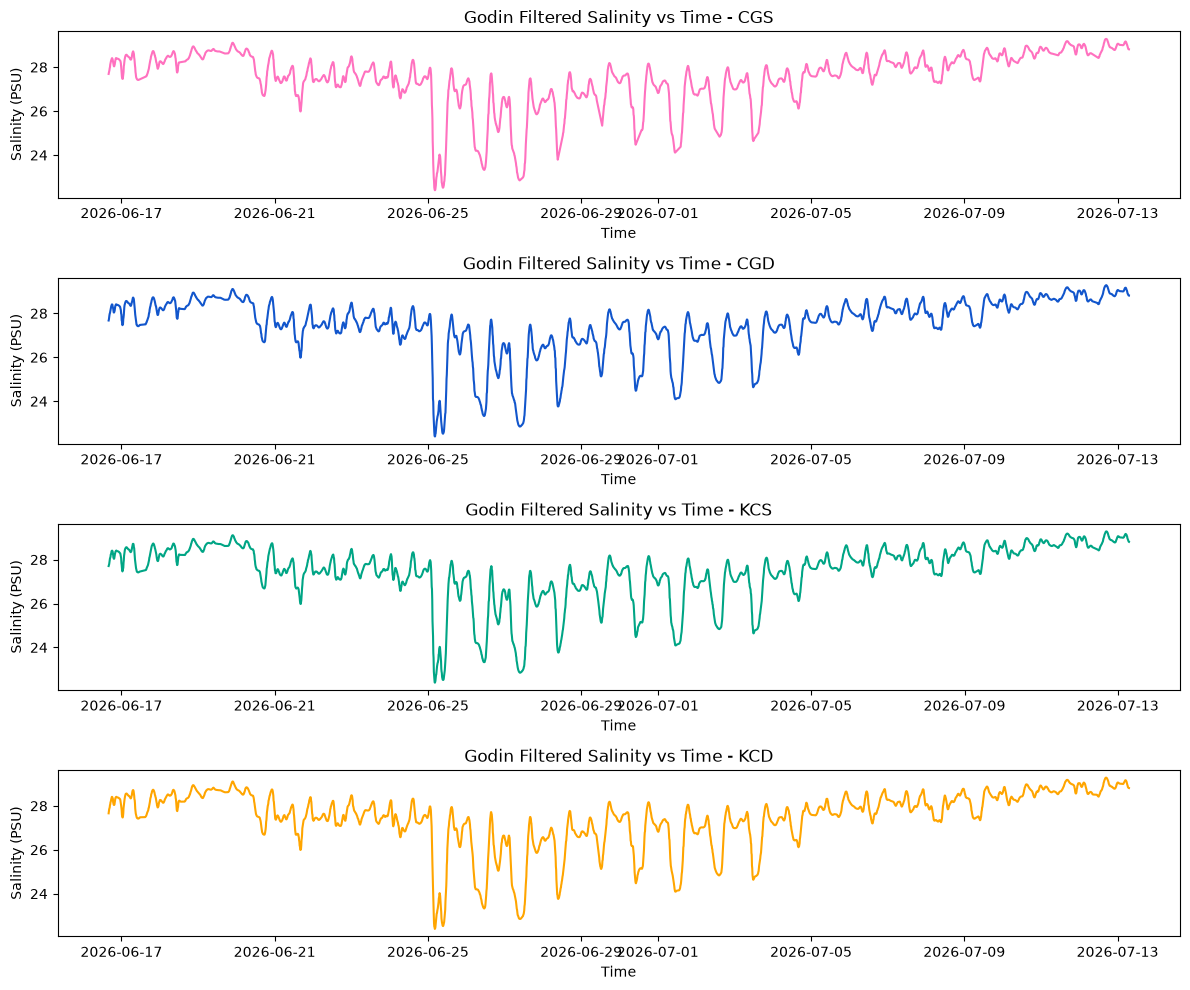

In [16]:
# Plot salinity vs time for each site jun - jul
fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(12, 10))

for i, site in enumerate(junJulSites):
    siteData = junJul26[junJul26['SITE_NAME'] == site]
    ax[i].plot(siteData['DATETIME'], siteData['godinSal'], label=f'Godin {site}', color=colors[i])
    ax[i].set_xlabel('Time')
    ax[i].set_ylabel('Salinity (PSU)')
    ax[i].set_title(f'Godin Filtered Salinity vs Time - {site}')
plt.tight_layout()
plt.show()

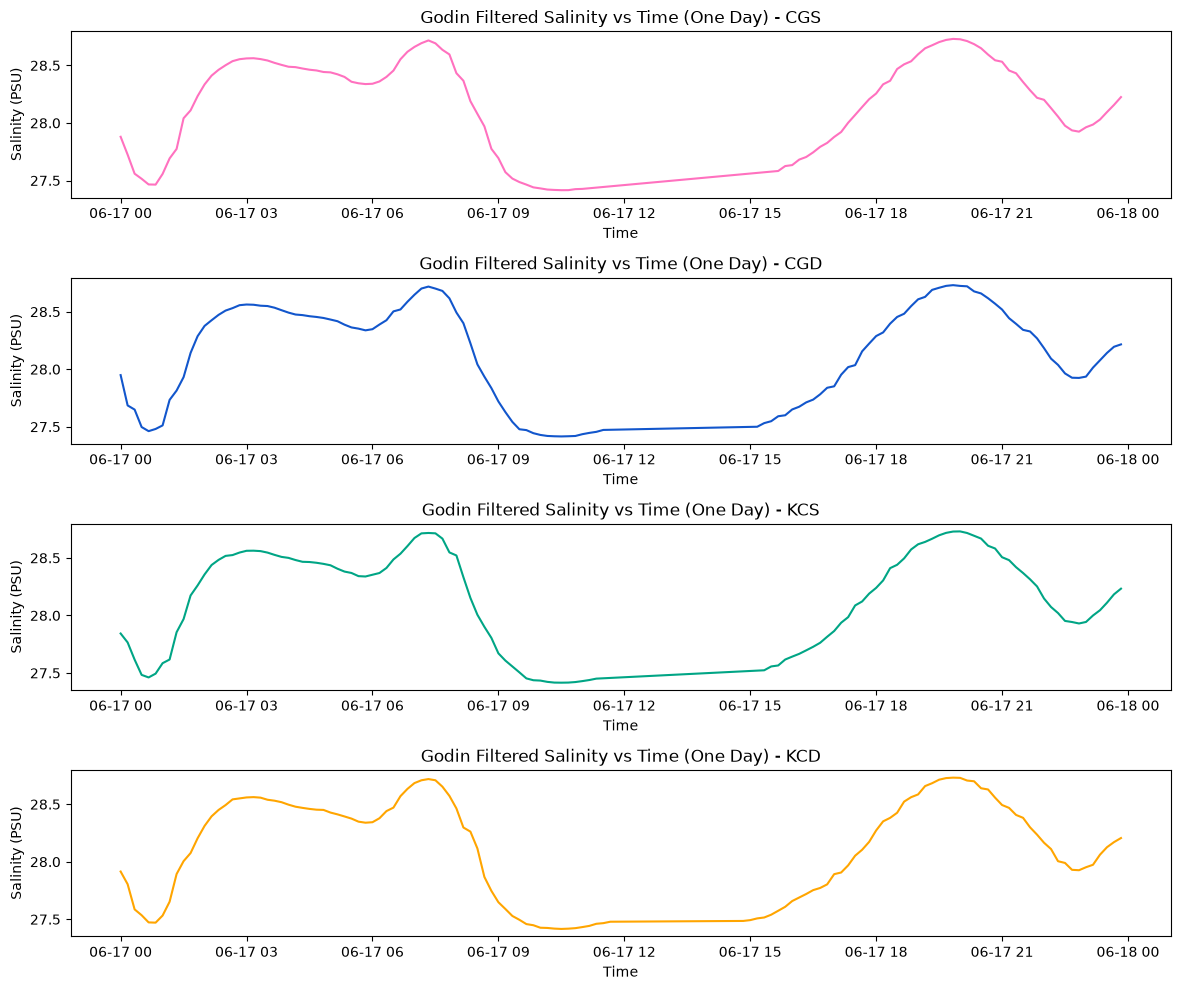

In [26]:
# Plot salinity vs time for each site jun - jul for a given day
fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(12, 10))
day = 17

for i, site in enumerate(junJulSites):
    siteData = junJul26[(junJul26['SITE_NAME'] == site) & (junJul26['DAY'] == day)]
    ax[i].plot(siteData['DATETIME'], siteData['godinSal'], label=f'Godin {site}', color=colors[i])
    ax[i].set_xlabel('Time')
    ax[i].set_ylabel('Salinity (PSU)')
    ax[i].set_title(f'Godin Filtered Salinity vs Time (One Day) - {site}')
plt.tight_layout()
plt.show()

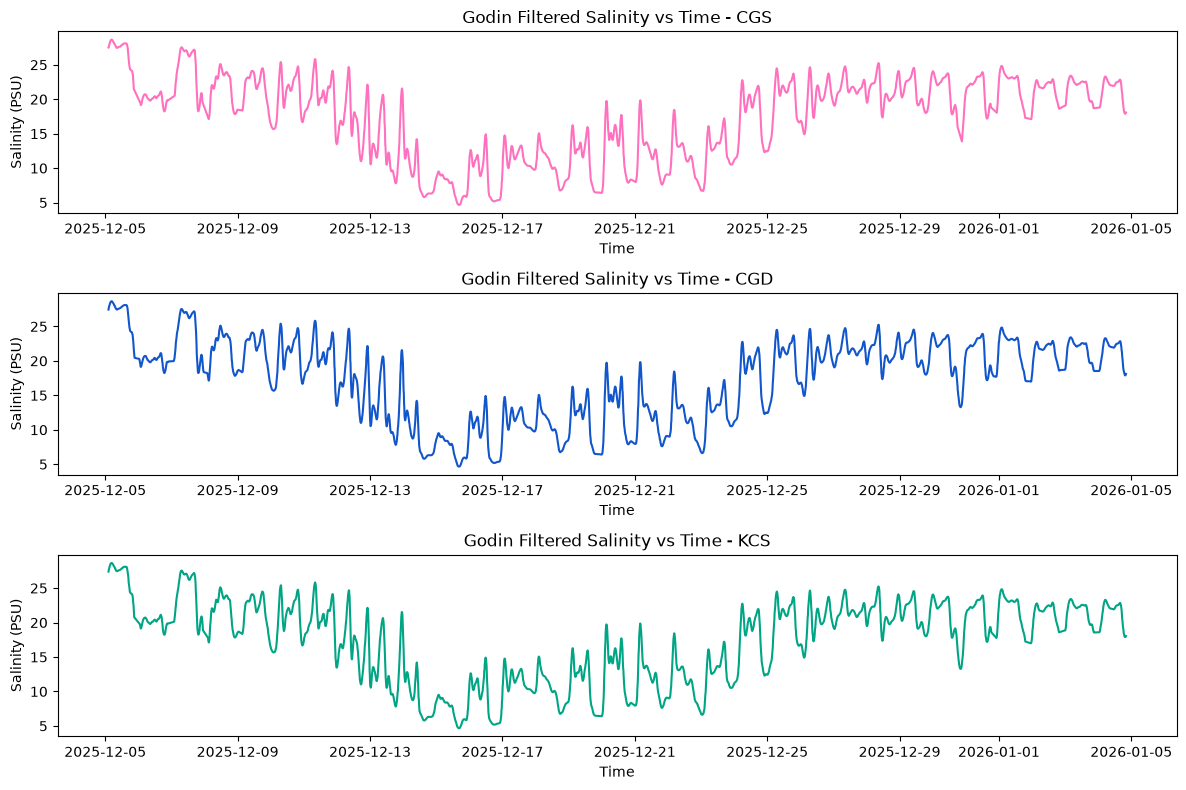

In [30]:
# Plot salinity vs time for each site dec - jan
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(12, 8))

for i, site in enumerate(decJanSites):
    siteData = decJan25[decJan25['SITE_NAME'] == site]
    ax[i].plot(siteData['DATETIME'], siteData['godinSal'], label=f'Godin {site}', color=colors[i])
    ax[i].set_xlabel('Time')
    ax[i].set_ylabel('Salinity (PSU)')
    ax[i].set_title(f'Godin Filtered Salinity vs Time - {site}')
plt.tight_layout()
plt.show()

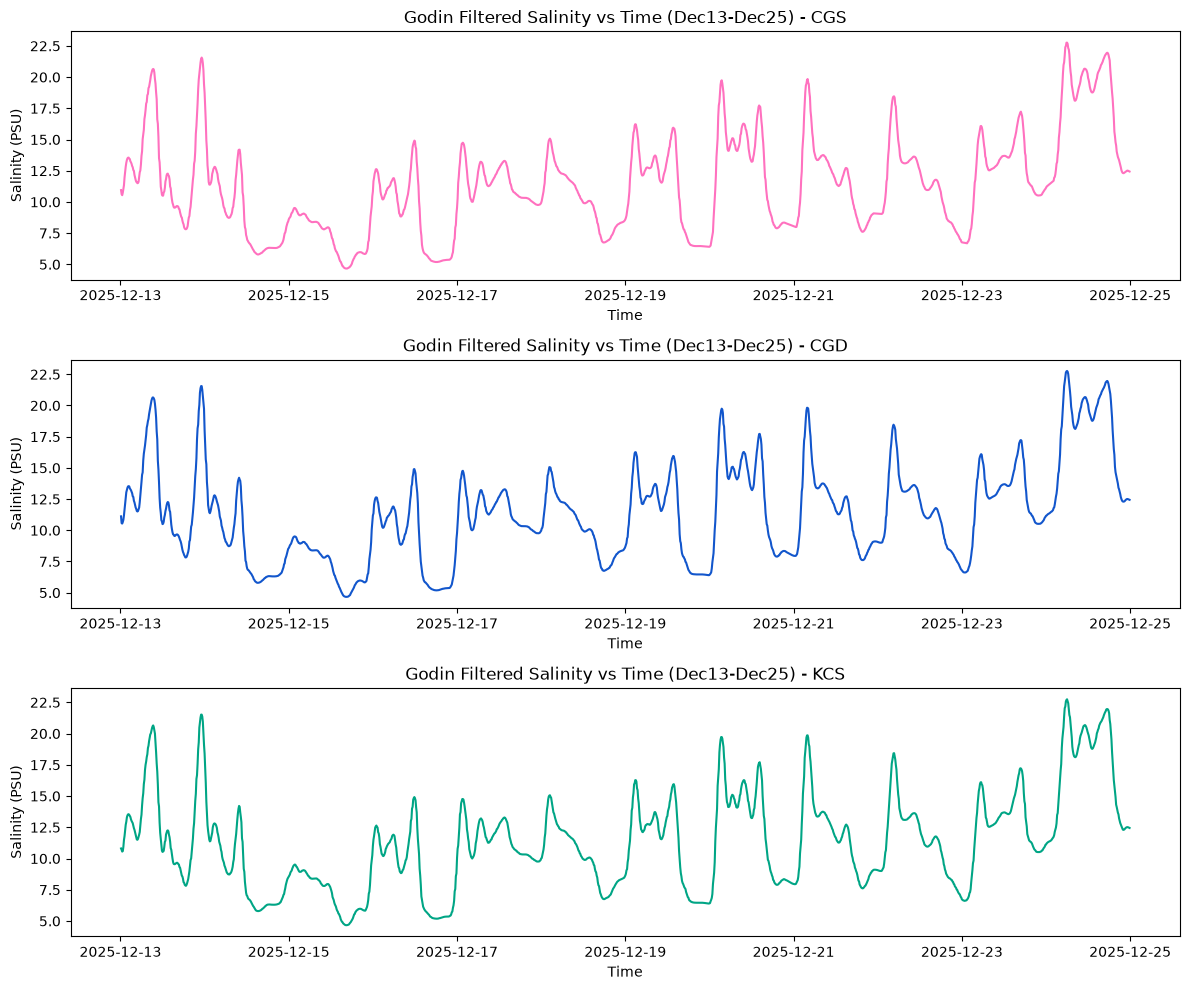

In [39]:
# Plot salinity vs time for each site dec - jan for a given day range
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(12, 10))
date1 = '2025-12-13'
date2 = '2025-12-25'
    
for i, site in enumerate(decJanSites):
    siteData = decJan25[(decJan25['SITE_NAME'] == site) & (decJan25['DATETIME'] > date1) & (decJan25['DATETIME'] < date2)]
    ax[i].plot(siteData['DATETIME'], siteData['godinSal'], label=f'Godin {site}', color=colors[i])
    ax[i].set_xlabel('Time')
    ax[i].set_ylabel('Salinity (PSU)')
    ax[i].set_title(f'Godin Filtered Salinity vs Time (Dec13-Dec25) - {site}')
plt.tight_layout()
plt.show()